In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed

output_dir = "./_Data/Test_four"
full_dir = "./_Data/Test_full"

In [1]:
# Download SWOT
# Still takes 2 mins even if everything already downloaded!
altimetry_downloader_aviso.get("SWOT_L3_LR_SSH_Expert", output_dir=output_dir, cycle_number=list(range(1,59)), pass_number=[201, 214, 479, 520])


NameError: name 'altimetry_downloader_aviso' is not defined

In [ ]:
# Skips chunks, may be better to download serially
passes = list(range(1,585)) # Swot has 584 passes
chunk_number = 6 
passes_per_chunk = len(passes) // chunk_number
chunks = [passes[i:i + passes_per_chunk] for i in range(0, len(passes), passes_per_chunk)]

def download_chunk(chunk):
    print(f"Downloading chunk: {chunk}")
    altimetry_downloader_aviso.get("SWOT_L3_LR_SSH_Expert", output_dir=full_dir, cycle_number=list(range(57,58)), pass_number=chunk)

with ThreadPoolExecutor(max_workers=(chunk_number + 1)) as executor:
    executor.map(download_chunk, chunks)

In [14]:
download_chunk(chunks[1]) # Download the last chunk

In [2]:
# Test SSH of cycle 57
data_paths = Path(full_dir).glob("SWOT_L3_LR_SSH_Expert_*.nc")
data_df = [xr.open_dataset(path) for path in data_paths]

In [7]:
bad = [i for i, df in enumerate(data_df)
       if np.ptp(((df['longitude'] + 180) % 360 - 180).values) > 180]
print(bad)

[0, 1, 2, 7, 9, 12, 16, 18, 20, 23, 24, 25, 29, 34, 37, 41, 53, 55, 56, 58, 61, 63, 64, 65, 70, 72, 73, 76, 77, 78, 81, 83, 84, 86, 89, 90, 91, 92, 97, 98, 102, 104, 109, 110, 112, 115, 116, 119, 122, 126, 127, 128, 129, 130, 133, 134, 136, 138, 147, 149, 155, 156, 159, 161, 166, 167, 169, 171, 173, 175, 176, 177, 178, 179, 180, 181, 182, 184, 185, 189, 192, 194, 195, 196, 197, 198, 200, 205, 210, 215, 216, 217, 221, 222, 223, 226, 229, 230, 233, 235, 237, 240, 241, 243, 244, 245, 249, 252, 256, 258, 262, 263, 266, 271, 272, 273, 274, 276, 277, 279, 280, 281, 282, 284, 285, 286, 287, 289, 292, 293, 294, 298, 300, 301, 304, 305, 307, 311, 312, 313, 315, 316, 318, 322, 323, 324, 325, 327, 328, 329, 330, 332, 333, 336, 337, 341, 342, 343, 344, 349, 352, 353, 355, 356, 368, 371, 372, 373, 375, 376, 378, 379, 382, 386, 388, 393, 394, 395, 398, 402, 403, 405, 406, 407, 409, 410, 411, 412, 415, 416, 417, 418, 419, 421, 422, 423, 424, 428, 429, 432, 434, 438, 439, 440, 442, 444, 445, 451, 453,

ValueError: x and y arguments to pcolormesh cannot have non-finite values or be of type numpy.ma.MaskedArray with masked values

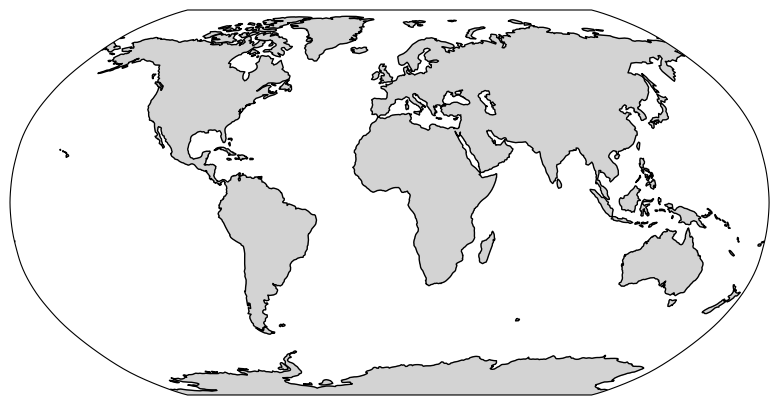

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5),subplot_kw={'projection': ccrs.Robinson()})
# Add grey continents using cfeature
for df in data_df[::5]:
    cb = ax.pcolormesh(df['longitude'], df['latitude'], df['ssha_filtered'], shading='auto',transform=ccrs.PlateCarree(), cmap='seismic', alpha=1, vmin=-1, vmax=1)
# Add coastlines
ax.set_facecolor('white')
ax.add_feature(
    cfeature.LAND,
    facecolor='lightgray',
    edgecolor='gray',
    linewidth=0.3,
    zorder=0
)
ax.coastlines()
#ax.set_extent([-5, 0, 60, 65], crs=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())
# Add colorbar
cbar = plt.colorbar(cb, ax=ax, orientation='horizontal', pad=0.05,extend='both', label='SSH Anomaly [m]')

In [2]:
# Load and inspect data
# Plot 1st cycle on map

data_paths = Path(output_dir).glob("SWOT_L3_LR_SSH_Expert*_214_*.nc")
data_df = [xr.open_dataset(path) for path in data_paths]

In [3]:
lines = []
pixels = []
for df in data_df:
    num_lines = df.sizes['num_lines']
    num_pixels = df.sizes['num_pixels']
    lines.append(num_lines)
    pixels.append(num_pixels)

# Assert all elements of lines and pixels are the same
assert all(x == lines[0] for x in lines), "Not all elements of lines are the same"
assert all(x == pixels[0] for x in pixels), "Not all elements of pixels are the same"

In [4]:
dfs_no_nadir = []
# Drop conflicting num_nadir dimenstion and i_num_line, i_num_pixel vals which depend on it
for df in data_df:
    try:
        df_dropped = df.drop_vars(['i_num_line', 'i_num_pixel'])
    except ValueError:
        print(df)
    dfs_no_nadir.append(df_dropped)

<xarray.Dataset> Size: 99MB
Dimensions:               (num_lines: 9860, num_pixels: 69)
Coordinates:
    latitude              (num_lines, num_pixels) float64 5MB ...
    longitude             (num_lines, num_pixels) float64 5MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/19)
    time                  (num_lines) datetime64[ns] 79kB ...
    calibration           (num_lines, num_pixels) float64 5MB ...
    cross_track_distance  (num_pixels) float64 552B ...
    dac                   (num_lines, num_pixels) float64 5MB ...
    internal_tide         (num_lines, num_pixels) float64 5MB ...
    mdt                   (num_lines, num_pixels) float64 5MB ...
    ...                    ...
    ugos_filtered         (num_lines, num_pixels) float64 5MB ...
    ugosa_filtered        (num_lines, num_pixels) float64 5MB ...
    ugosa_unfiltered      (num_lines, num_pixels) float64 5MB ...
    vgos_filtered         (num_lines, num_pixels) float64 5MB ...
    vgosa_fi

In [5]:
# Stack all dataframes into one
data_df = xr.concat(dfs_no_nadir, dim='cycle_number')
data_df["ssha_detided"] = data_df["ssha_filtered"] + data_df["ocean_tide"]

: 

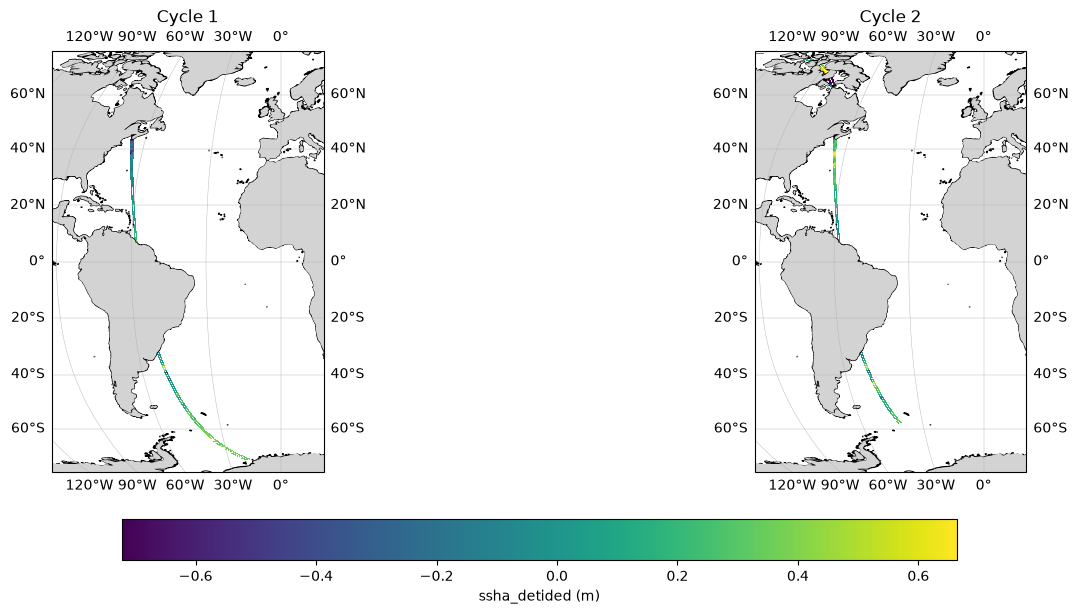

In [55]:
# Example plot of a few cycles 
cycles = [1,2]
vmin, vmax = data_df["ssha_detided"].sel(cycle_number=cycles).quantile([0.02, 0.98]).values

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    subplot_kw={"projection": ccrs.Robinson()},
    constrained_layout=True,
)

for ax, c in zip(axes, cycles):
    d = data_df.sel(cycle_number=c)
    lon = d["longitude"]
    lon = ((lon + 180) % 360) - 180      # wrap to -180..180 to avoid streaks
    m = ax.pcolormesh(
        lon, d["latitude"], d["ssha_detided"],
        shading="auto", transform=ccrs.PlateCarree(),
        cmap="viridis", vmin=vmin, vmax=vmax,
    )
    ax.coastlines(resolution="50m")
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
    ax.gridlines(draw_labels=True, linewidth=0.3)
    ax.set_title(f"Cycle {int(c)}")

fig.colorbar(m, ax=axes, orientation="horizontal", shrink=0.6, pad=0.05,
             label="ssha_detided (m)")
plt.show()

In [ ]:
tnum = mdates.date2num(data_df["time"].values) 

NameError: name 'tnum' is not defined

In [ ]:
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
min_obs = 40          # 17 parameters, so leave margin for NaNs

tnum = mdates.date2num(data_df["time"].values)             # (cycle, num_lines), days
h = data_df["ssha_detided"].values                         # (cycle, num_lines, num_pixels)
lat = data_df["latitude"].values                           # (num_lines, num_pixels)

def fit_line(j):
    npx = h.shape[2]
    amp = np.full((len(constits), npx), np.nan)
    pha = np.full((len(constits), npx), np.nan)
    t_j = tnum[:, j]
    for i in range(npx):
        y = h[:, j, i]
        ok = np.isfinite(y) & np.isfinite(t_j)
        if ok.sum() < min_obs or not np.isfinite(lat[j, i]):
            continue
        try:
            c = solve(t_j[ok], y[ok], lat=lat[j, i], constit=constits,
                      nodal=False, trend=False, method="ols",
                      conf_int="none", verbose=False)
        except Exception:
            continue
        names = list(c.name)
        for k, name in enumerate(constits):
            if name in names:
                idx = names.index(name)
                amp[k, i], pha[k, i] = c.A[idx], c.g[idx]
    return amp, pha

# test on a small slice first
test = [fit_line(j) for j in range(len(h))]
res = test            
#res = Parallel(n_jobs=3, batch_size=50)(delayed(fit_line)(j) for j in range(h.shape[1]))         
amp = np.stack([r[0] for r in res], axis=1)    # (constituent, n_lines, num_pixels)
pha = np.stack([r[1] for r in res], axis=1)

lat = np.asarray(df["latitude"].values)
lon = np.asarray(df["longitude"].values)
tide_fit = xr.Dataset(
    {"amplitude": (("constituent", "num_lines", "num_pixels"), amp),
     "phase": (("constituent", "num_lines", "num_pixels"), pha)},
    coords={"constituent": constits,
            "latitude": (("num_lines", "num_pixels"), lat[:]),
            "longitude": (("num_lines", "num_pixels"), lon[:])},
)
tide_fit["amplitude"].attrs["units"] = "m"
tide_fit["phase"].attrs["units"] = "degrees (Greenwich)"

: 

In [8]:
# Run fes/tpxo at the same points and compare to utide
np.unique(tide_fit['amplitude'])

array([nan])

In [93]:
import numpy as np
import matplotlib.dates as mdates
from utide import solve

tnum = mdates.date2num(data_df["time"].values)           # (cycle, num_lines)
h = data_df["ssha_detided"].values
lat = np.asarray(data_df["latitude"].values)

nvalid = np.isfinite(h).sum(axis=0)
j, i = np.unravel_index(np.argmax(nvalid), nvalid.shape)   # point with the most valid cycles
print("point:", j, i, "valid cycles:", nvalid[j, i], "lat:", lat[j, i])

t = tnum[:, j]
y = h[:, j, i]
ok = np.isfinite(y) & np.isfinite(t)
print("n ok:", ok.sum(), "t range:", t[ok].min(), t[ok].max(), "dtype:", t.dtype)

constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
c = solve(t[ok], y[ok], lat=float(lat[j, i]), constit=constits,
          nodal=False, trend=False, method="ols",
          conf_int="none", verbose=True)
print(c.name, c.A)

point: 2163 39 valid cycles: 57 lat: 49.007574
n ok: 57 t range: 19566.849506099214 20756.13386501638 dtype: float64
solve: matrix prep ... solution ... done.
['P1' 'K2' 'S2' 'K1' 'M2' 'Q1' 'N2' 'O1'] [5.15441629e+11 3.64462213e+11 3.28374911e+11 1.76888751e+11
 1.53212692e+11 1.26820077e+11 5.84599226e+10 3.34801346e+10]


In [94]:
print("y min/max/std:", y[ok].min(), y[ok].max(), y[ok].std())
print("dt min/max (d):", np.diff(np.sort(t[ok])).min(), np.diff(np.sort(t[ok])).max())

# 1) Same harmonic model solved directly, centered time
import numpy as np
freqs = {"M2":1.932274,"S2":2.0,"N2":1.895982,"K2":2.005476,
         "K1":1.002738,"O1":0.929536,"P1":0.997262,"Q1":0.893244}
f = np.array([freqs[c] for c in constits])
tc = t[ok] - t[ok].mean()
A = np.hstack([np.cos(2*np.pi*np.outer(tc, f)),
               np.sin(2*np.pi*np.outer(tc, f)),
               np.ones((tc.size, 1))])
coef, *_ = np.linalg.lstsq(A, y[ok], rcond=None)
amp_ls = np.hypot(coef[:8], coef[8:16])
print(dict(zip(constits, amp_ls.round(4))))
print("residual std:", (y[ok] - A @ coef).std())

# 2) utide with fewer constituents
c2 = solve(t[ok], y[ok], lat=float(lat[j, i]), constit=["M2","S2","N2","K1","O1"],
           nodal=False, trend=False, method="ols", conf_int="none", verbose=False)
print(c2.name, c2.A)

y min/max/std: -1.8065 2.0465 0.9406378534412498
dt min/max (d): 0.0 41.72928233607672
{'M2': np.float64(1.1767), 'S2': np.float64(0.388), 'N2': np.float64(0.2223), 'K2': np.float64(0.1511), 'K1': np.float64(0.2963), 'O1': np.float64(0.2611), 'P1': np.float64(0.086), 'Q1': np.float64(0.0463)}
residual std: 0.08161256441369756
['K1' 'S2' 'M2' 'O1' 'N2'] [9.37867358e+11 7.19072924e+11 5.26902915e+11 3.75005286e+11
 9.06347882e+10]


In [86]:
nvalid = np.isfinite(h).sum(axis=0)                 # (num_lines, num_pixels), valid cycles per point

print("points with >= 40 valid cycles:", int((nvalid >= 40).sum()), "of", nvalid.size)
print("points with >= 30 valid cycles:", int((nvalid >= 30).sum()))
print("max valid cycles at any point:", int(nvalid.max()))

good_lines = np.where((nvalid >= 40).any(axis=1))[0]
print("lines with usable points:", good_lines.size, "range:", good_lines.min() if good_lines.size else None,
      good_lines.max() if good_lines.size else None)

points with >= 40 valid cycles: 196758 of 680340
points with >= 30 valid cycles: 211431
max valid cycles at any point: 57
lines with usable points: 3893 range: 1294 8334
